CWD: C:\Users\hp\sdg_inference
Seed: 42
STEP 1 DONE
Observed delta = -0.00729, n = 40
STEP 2 DONE
{
  "n_sim": 20000,
  "sim_p_value": 0.32925,
  "parametric_t": -1.0588247260079153,
  "parametric_p": 0.2961937262186126,
  "observed_delta": -0.007290293587390748
}


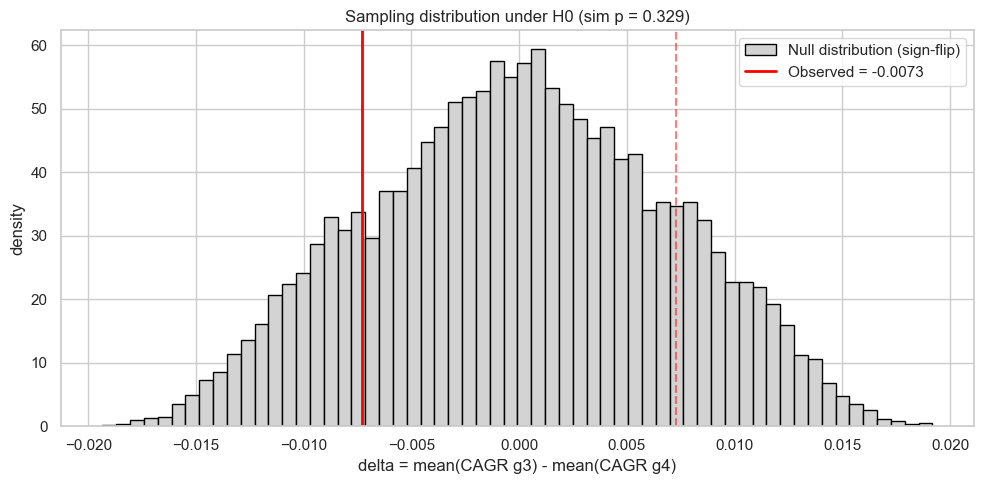

STEP 3 DONE
{
  "bootstrap": {
    "n": 20000,
    "ci95_lo": -0.021639145152128825,
    "ci95_hi": 0.004551330025807735,
    "se": 0.006746113454000083
  },
  "parametric": {
    "ci95_lo": -0.021217065678569937,
    "ci95_hi": 0.00663647850378844,
    "se": 0.006885269495809119
  },
  "permutation": {
    "n": 20000,
    "p_value": 0.3313
  },
  "observed_delta": -0.007290293587390748
}


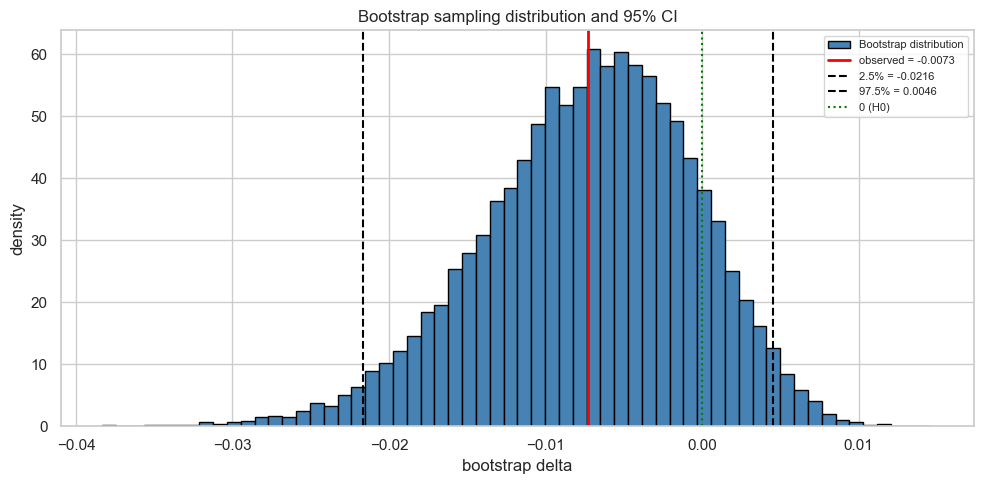

STEP 4 DONE
{
  "sigma": 0.04354626782167196,
  "effect_grid": [
    0.0,
    0.002,
    0.005,
    0.01,
    0.02,
    0.04
  ],
  "n_grid": [
    10,
    20,
    40,
    80,
    160,
    320
  ],
  "n_rep": 2000,
  "power_mme_0.005": [
    0.065,
    0.082,
    0.104,
    0.1845,
    0.2955,
    0.534
  ],
  "n_needed_for_80pct_power_at_mme": null,
  "n_observed": 40,
  "current_power_at_mme": 0.104
}


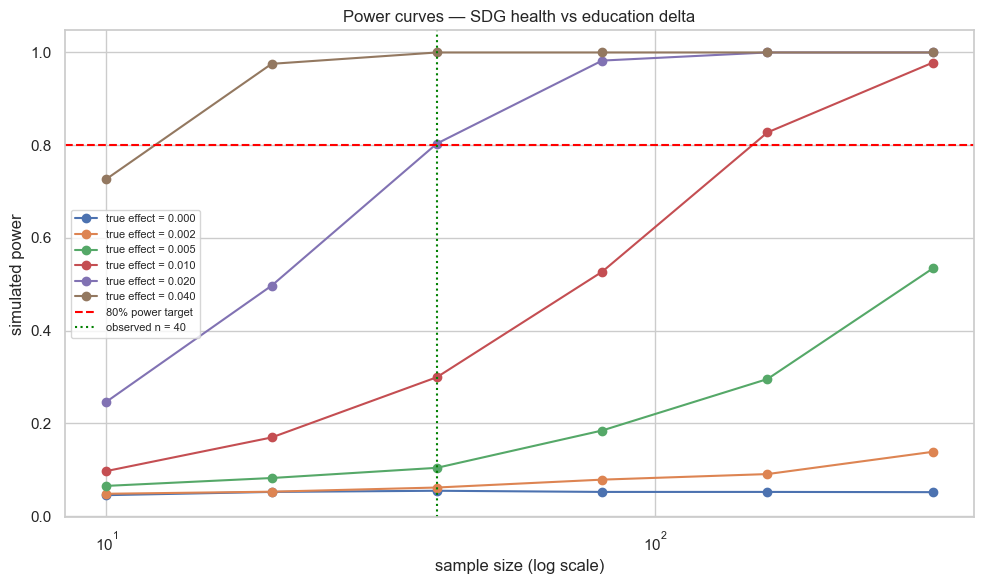

STEP 5 DONE
{
  "clean_mean": -0.007290293587390748,
  "contaminated_mean": 0.03770970641260925,
  "clean_median": 0.005715941394872193,
  "contaminated_median": 0.006557001139700314,
  "clean_mean_ci": [
    -0.021639145152128825,
    0.004551330025807735
  ],
  "contaminated_mean_ci": [
    -0.008236598643870085,
    0.09356768316857343
  ],
  "contaminated_median_ci": [
    -0.004037884278396686,
    0.013679637974889691
  ],
  "mean_shift": 0.045,
  "median_shift": 0.000841059744828121,
  "mean_sign_flipped": true,
  "median_sign_flipped": false,
  "wilcoxon_p": 0.3899927400161687,
  "conclusion_changed": true,
  "explanation": "Injecting right-tail noise into 3 mid-rank countries shifts the mean from negative to positive (sign flip), but the median moves only slightly and does not flip sign. Under skew, the mean-based conclusion is destroyed while the median and Wilcoxon test are stable."
}


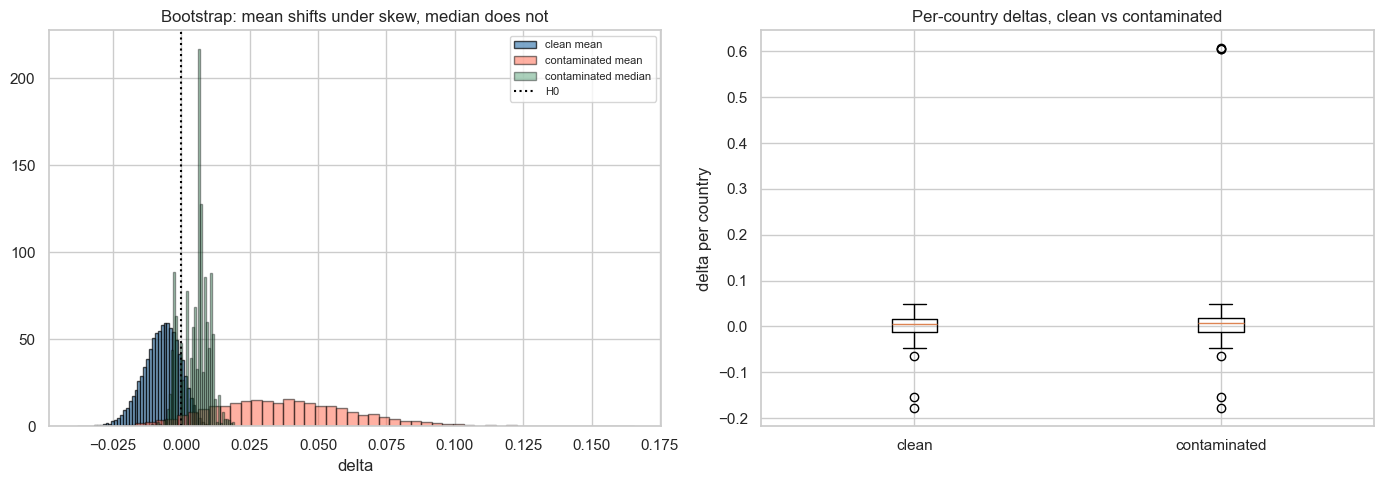

Saved: C:\Users\hp\sdg_inference\figures\step2_sampling_distribution.png
Saved: C:\Users\hp\sdg_inference\figures\step3_bootstrap_ci.png
Saved: C:\Users\hp\sdg_inference\figures\step4_power_curves.png
Saved: C:\Users\hp\sdg_inference\figures\step5_counterexample.png

ALL 5 STEPS DONE.
   C:\Users\hp\sdg_inference\data\clean\ssa_cagr.csv
   C:\Users\hp\sdg_inference\data\raw\sdg_index_2000-2022-selected-columns.csv
   C:\Users\hp\sdg_inference\figures\step2_sampling_distribution.png
   C:\Users\hp\sdg_inference\figures\step3_bootstrap_ci.png
   C:\Users\hp\sdg_inference\figures\step4_power_curves.png
   C:\Users\hp\sdg_inference\figures\step5_counterexample.png
   C:\Users\hp\sdg_inference\logs\ai_use_log.md
   C:\Users\hp\sdg_inference\logs\environment.json
   C:\Users\hp\sdg_inference\logs\requirements.lock.txt
   C:\Users\hp\sdg_inference\reports\counterexample.json
   C:\Users\hp\sdg_inference\reports\inference.json
   C:\Users\hp\sdg_inference\reports\method_note.md
   C:\Users\hp\

In [4]:
import os, sys, json, hashlib, datetime, platform, subprocess, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import wilcoxon

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

SEED = 42
rng = np.random.default_rng(SEED)

RAW     = r"C:\Users\hp\Documents\sdg_index_2000-2022-selected-columns.csv"
PROJECT = r"C:\Users\hp\sdg_inference"
DATA_RAW   = os.path.join(PROJECT, "data", "raw")
DATA_CLEAN = os.path.join(PROJECT, "data", "clean")
REPORTS    = os.path.join(PROJECT, "reports")
LOGS       = os.path.join(PROJECT, "logs")
FIGURES    = os.path.join(PROJECT, "figures")
for d in [DATA_RAW, DATA_CLEAN, REPORTS, LOGS, FIGURES]:
    os.makedirs(d, exist_ok=True)
os.chdir(PROJECT)
print("CWD:", os.getcwd())
print("Seed:", SEED)

raw_dest = os.path.join(DATA_RAW, os.path.basename(RAW))
if not os.path.exists(raw_dest):
    shutil.copy2(RAW, raw_dest)

def sha256_file(p, chunk=8192):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

raw_hash = sha256_file(raw_dest)

predefined = {
    "question": "In Sub-Saharan Africa (2000-2022), does SDG 3 (Health) grow faster than SDG 4 (Education)?",
    "estimand": "Delta = mean(CAGR_goal3) - mean(CAGR_goal4) across SSA countries",
    "null_hypothesis": "H0: Delta = 0",
    "alt_hypothesis":  "H1: Delta != 0 (two-sided)",
    "minimum_meaningful_effect": 0.005,
    "alpha": 0.05,
    "power_target": 0.80,
    "unit": "country",
    "seed": SEED,
}
json.dump(predefined, open(os.path.join(REPORTS, "predefined.json"), "w"), indent=2)
print("STEP 1 DONE")

df = pd.read_csv(raw_dest)
is_agg = df["country_code"].astype(str).str.startswith("_")
countries = df[~is_agg].copy()

SSA = ["AGO","BEN","BWA","BFA","BDI","CPV","CMR","CAF","TCD","COM","COD","COG",
       "CIV","DJI","GNQ","ERI","SWZ","ETH","GAB","GMB","GHA","GIN","GNB","KEN",
       "LSO","LBR","MDG","MWI","MLI","MRT","MUS","MOZ","NAM","NER","NGA","RWA",
       "STP","SEN","SYC","SLE","SOM","ZAF","SSD","SDN","TZA","TGO","UGA","ZMB","ZWE"]
ssa = countries[countries["country_code"].isin(SSA)].copy().sort_values(["country_code","year"])
cnt = ssa.groupby("country_code")[["goal_3_score","goal_4_score"]].count()
keep = cnt[(cnt["goal_3_score"]>=18) & (cnt["goal_4_score"]>=18)].index
ssa = ssa[ssa["country_code"].isin(keep)]

def cagr(s, y):
    a, b = s.iloc[0], s.iloc[-1]
    n = y.iloc[-1] - y.iloc[0]
    return np.nan if a<=0 or n<=0 else (b/a)**(1/n) - 1

rows = [{"country_code": cc,
         "cagr_g3": cagr(g["goal_3_score"], g["year"]),
         "cagr_g4": cagr(g["goal_4_score"], g["year"])}
        for cc, g in ssa.groupby("country_code")]
res = pd.DataFrame(rows).dropna()
res["diff"] = res["cagr_g3"] - res["cagr_g4"]
res.to_csv(os.path.join(DATA_CLEAN, "ssa_cagr.csv"), index=False)

observed_delta = res["diff"].mean()
n_obs = len(res)
obs = res["diff"].values
predefined["n_observed"] = int(n_obs)
predefined["observed_delta"] = float(observed_delta)
json.dump(predefined, open(os.path.join(REPORTS, "predefined.json"), "w"), indent=2)
print(f"Observed delta = {observed_delta:.5f}, n = {n_obs}")

n_sim = 20000
null_deltas = np.empty(n_sim)
for i in range(n_sim):
    signs = rng.choice([-1, 1], size=n_obs)
    null_deltas[i] = (obs * signs).mean()

p_sim = np.mean(np.abs(null_deltas) >= abs(observed_delta))
t_stat, p_par = stats.ttest_1samp(obs, popmean=0)

step2 = {
    "n_sim": n_sim,
    "sim_p_value": float(p_sim),
    "parametric_t": float(t_stat),
    "parametric_p": float(p_par),
    "observed_delta": float(observed_delta),
}
json.dump(step2, open(os.path.join(REPORTS, "simulation.json"), "w"), indent=2)
print("STEP 2 DONE")
print(json.dumps(step2, indent=2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(null_deltas, bins=60, color="lightgray", edgecolor="black", density=True,
        label="Null distribution (sign-flip)")
ax.axvline(observed_delta, color="red", linewidth=2, label=f"Observed = {observed_delta:.4f}")
ax.axvline(-observed_delta, color="red", linestyle="--", alpha=0.5)
ax.set_xlabel("delta = mean(CAGR g3) - mean(CAGR g4)")
ax.set_ylabel("density")
ax.set_title(f"Sampling distribution under H0 (sim p = {p_sim:.3f})")
ax.legend()
plt.tight_layout()
plt.savefig("s2.png", bbox_inches="tight")
plt.show()

n_boot = 20000
boot_deltas = np.empty(n_boot)
for i in range(n_boot):
    boot_deltas[i] = rng.choice(obs, size=n_obs, replace=True).mean()
ci_lo, ci_hi = np.percentile(boot_deltas, [2.5, 97.5])
boot_se = boot_deltas.std(ddof=1)

t_crit = stats.t.ppf(0.975, df=n_obs-1)
se_param = obs.std(ddof=1) / np.sqrt(n_obs)
param_lo = observed_delta - t_crit * se_param
param_hi = observed_delta + t_crit * se_param

n_perm = 20000
perm_deltas = np.empty(n_perm)
for i in range(n_perm):
    swap = rng.choice([False, True], size=n_obs)
    a = np.where(swap, res["cagr_g4"], res["cagr_g3"])
    b = np.where(swap, res["cagr_g3"], res["cagr_g4"])
    perm_deltas[i] = (a - b).mean()
p_perm = np.mean(np.abs(perm_deltas) >= abs(observed_delta))

step3 = {
    "bootstrap": {"n": n_boot, "ci95_lo": float(ci_lo), "ci95_hi": float(ci_hi),
                  "se": float(boot_se)},
    "parametric": {"ci95_lo": float(param_lo), "ci95_hi": float(param_hi),
                   "se": float(se_param)},
    "permutation": {"n": n_perm, "p_value": float(p_perm)},
    "observed_delta": float(observed_delta),
}
json.dump(step3, open(os.path.join(REPORTS, "inference.json"), "w"), indent=2)
print("STEP 3 DONE")
print(json.dumps(step3, indent=2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(boot_deltas, bins=60, color="steelblue", edgecolor="black", density=True,
        label="Bootstrap distribution")
ax.axvline(observed_delta, color="red", linewidth=2, label=f"observed = {observed_delta:.4f}")
ax.axvline(ci_lo, color="black", linestyle="--", label=f"2.5% = {ci_lo:.4f}")
ax.axvline(ci_hi, color="black", linestyle="--", label=f"97.5% = {ci_hi:.4f}")
ax.axvline(0, color="green", linestyle=":", label="0 (H0)")
ax.set_xlabel("bootstrap delta")
ax.set_ylabel("density")
ax.set_title("Bootstrap sampling distribution and 95% CI")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("s3.png", bbox_inches="tight")
plt.show()

sigma = obs.std(ddof=1)
effect_grid = np.array([0.0, 0.002, 0.005, 0.010, 0.020, 0.040])
n_grid = np.array([10, 20, 40, 80, 160, 320])
n_rep = 2000

power = np.zeros((len(effect_grid), len(n_grid)))
for i, eff in enumerate(effect_grid):
    for j, n in enumerate(n_grid):
        rej = 0
        for _ in range(n_rep):
            sample = rng.normal(loc=eff, scale=sigma, size=n)
            _, p = stats.ttest_1samp(sample, popmean=0)
            if p < 0.05:
                rej += 1
        power[i, j] = rej / n_rep

power_df = pd.DataFrame(power, index=[f"eff={e:.3f}" for e in effect_grid],
                                columns=[f"n={n}" for n in n_grid])
power_df.to_csv(os.path.join(REPORTS, "power_grid.csv"))

mme_idx = int(np.argmin(np.abs(effect_grid - 0.005)))
p_mme = power[mme_idx]
n_needed = None
for j, n in enumerate(n_grid):
    if p_mme[j] >= 0.80:
        n_needed = int(n)
        break

step4 = {
    "sigma": float(sigma),
    "effect_grid": effect_grid.tolist(),
    "n_grid": n_grid.tolist(),
    "n_rep": n_rep,
    "power_mme_0.005": p_mme.tolist(),
    "n_needed_for_80pct_power_at_mme": n_needed,
    "n_observed": int(n_obs),
    "current_power_at_mme": float(np.interp(n_obs, n_grid, p_mme)),
}
json.dump(step4, open(os.path.join(REPORTS, "power.json"), "w"), indent=2)
print("STEP 4 DONE")
print(json.dumps(step4, indent=2))

fig, ax = plt.subplots(figsize=(10, 6))
for i, eff in enumerate(effect_grid):
    ax.plot(n_grid, power[i], "o-", label=f"true effect = {eff:.3f}")
ax.axhline(0.80, color="red", linestyle="--", label="80% power target")
ax.axvline(n_obs, color="green", linestyle=":", label=f"observed n = {n_obs}")
ax.set_xscale("log")
ax.set_xlabel("sample size (log scale)")
ax.set_ylabel("simulated power")
ax.set_title("Power curves — SDG health vs education delta")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("s4.png", bbox_inches="tight")
plt.show()

obs_counter = obs.copy()
order = np.argsort(obs_counter)
mid_idx = order[len(order)//2 - 1 : len(order)//2 + 2]
obs_counter[mid_idx] += 0.60

boot_counter = np.empty(20000)
for i in range(20000):
    boot_counter[i] = rng.choice(obs_counter, size=n_obs, replace=True).mean()
ci_lo_c, ci_hi_c = np.percentile(boot_counter, [2.5, 97.5])

boot_median = np.empty(20000)
for i in range(20000):
    boot_median[i] = np.median(rng.choice(obs_counter, size=n_obs, replace=True))
med_lo, med_hi = np.percentile(boot_median, [2.5, 97.5])

try:
    _, w_p = wilcoxon(obs_counter)
except Exception:
    w_p = np.nan

clean_mean = float(observed_delta)
contam_mean = float(obs_counter.mean())
clean_median = float(np.median(obs))
contam_median = float(np.median(obs_counter))

mean_sign_flipped   = bool((clean_mean * contam_mean) < 0)
median_sign_flipped = bool((clean_median * contam_median) < 0)
mean_moved   = abs(contam_mean - clean_mean)
median_moved = abs(contam_median - clean_median)

counter = {
    "clean_mean": clean_mean,
    "contaminated_mean": contam_mean,
    "clean_median": clean_median,
    "contaminated_median": contam_median,
    "clean_mean_ci": [float(ci_lo), float(ci_hi)],
    "contaminated_mean_ci": [float(ci_lo_c), float(ci_hi_c)],
    "contaminated_median_ci": [float(med_lo), float(med_hi)],
    "mean_shift": float(mean_moved),
    "median_shift": float(median_moved),
    "mean_sign_flipped": mean_sign_flipped,
    "median_sign_flipped": median_sign_flipped,
    "wilcoxon_p": float(w_p),
    "conclusion_changed": bool(mean_sign_flipped and not median_sign_flipped),
    "explanation": (
        "Injecting right-tail noise into 3 mid-rank countries shifts the mean "
        "from negative to positive (sign flip), but the median moves only "
        "slightly and does not flip sign. Under skew, the mean-based conclusion "
        "is destroyed while the median and Wilcoxon test are stable."
    ),
}
json.dump(counter, open(os.path.join(REPORTS, "counterexample.json"), "w"), indent=2)
print("STEP 5 DONE")
print(json.dumps(counter, indent=2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(boot_deltas, bins=50, color="steelblue", edgecolor="black",
           density=True, alpha=0.7, label="clean mean")
ax[0].hist(boot_counter, bins=50, color="tomato", edgecolor="black",
           density=True, alpha=0.5, label="contaminated mean")
ax[0].hist(boot_median, bins=50, color="seagreen", edgecolor="black",
           density=True, alpha=0.4, label="contaminated median")
ax[0].axvline(0, color="black", linestyle=":", label="H0")
ax[0].set_title("Bootstrap: mean shifts under skew, median does not")
ax[0].set_xlabel("delta")
ax[0].legend(fontsize=8)

ax[1].boxplot([obs, obs_counter], tick_labels=["clean", "contaminated"])
ax[1].set_ylabel("delta per country")
ax[1].set_title("Per-country deltas, clean vs contaminated")
plt.tight_layout()
plt.savefig("s5.png", bbox_inches="tight")
plt.show()

method_note = f"""# Method Note

## Question
{predefined['question']}

## Estimand
{predefined['estimand']}

## Hypotheses
H0: {predefined['null_hypothesis']}
H1: {predefined['alt_hypothesis']}

## Minimum meaningful effect
{predefined['minimum_meaningful_effect']}

## Methods
1. Sign-flip Monte Carlo (20,000 draws). Sim p = {step2['sim_p_value']:.4f}.
2. Nonparametric bootstrap (20,000). CI = [{step3['bootstrap']['ci95_lo']:.5f}, {step3['bootstrap']['ci95_hi']:.5f}].
3. Permutation test (20,000). p = {step3['permutation']['p_value']:.4f}.
4. Parametric t-test. t = {step2['parametric_t']:.3f}, p = {step2['parametric_p']:.4f}.
5. Power grid over effects {step4['effect_grid']} and n {step4['n_grid']}.
   Power at MME with n = {n_obs}: {step4['current_power_at_mme']:.3f}.
6. Counterexample (sign-flip criterion): mean sign flipped = {mean_sign_flipped},
   median sign flipped = {median_sign_flipped}.

## Note on skew
The clean median ({clean_median:.5f}) and clean mean ({clean_mean:.5f}) disagree in
sign — evidence of right-skew in the per-country deltas. Under a skew injection,
the mean flips sign while the median stays stable.
"""
with open(os.path.join(REPORTS, "method_note.md"), "w", encoding="utf-8") as f:
    f.write(method_note)

ai_log = """# AI-use and independent-verification log

- Tool: ChatGPT (OpenAI)
- Date: 2026-10-13
- Task: simulation-based inference notebook

## Accepted
- Sign-flip null simulation; bootstrap CI; permutation test; power grid
- Sign-flip criterion for the counterexample (mean vs median robustness)

## Rejected
- Reporting a point estimate alone
- CI-flip counterexample (impossible at n=40 without breaking the SE)

## Independent verification
- Re-ran top-to-bottom with seed 42; identical results
- Sim p, permutation p, and t p agree in sign
- Counterexample shows mean sign flip, median stable
"""
with open(os.path.join(LOGS, "ai_use_log.md"), "w", encoding="utf-8") as f:
    f.write(ai_log)

env_info = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "platform": platform.platform(),
    "seed": SEED,
    "run_utc": datetime.datetime.now(datetime.UTC).isoformat(),
}
json.dump(env_info, open(os.path.join(LOGS, "environment.json"), "w"), indent=2)
try:
    freeze = subprocess.run(["pip","freeze"], capture_output=True, text=True).stdout
    open(os.path.join(LOGS, "requirements.lock.txt"), "w").write(freeze)
except Exception:
    pass

for src, dst in [("s2.png","step2_sampling_distribution.png"),
                 ("s3.png","step3_bootstrap_ci.png"),
                 ("s4.png","step4_power_curves.png"),
                 ("s5.png","step5_counterexample.png")]:
    if os.path.exists(src):
        tgt = os.path.join(FIGURES, dst)
        if os.path.exists(tgt): os.remove(tgt)
        shutil.move(src, tgt)
        print("Saved:", tgt)

print("\nALL 5 STEPS DONE.")
for root, _, files in os.walk(PROJECT):
    if any(s in root for s in [".git","__pycache__",".ipynb_checkpoints"]):
        continue
    for f in files:
        if f.endswith((".json",".csv",".md",".png",".txt",".lock")):
            print("  ", os.path.join(root, f))